# Main Questions:

1) Does higher education always mean higher pay? Or do skills count outweigh the education?
2) Do bigger companies pay more for the same roles versus smaller companies?
3) Does pay differ among countries when you control for education and experience?

In [2]:
# Code Block 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [3]:
# Code Block 2
%pip install 'kagglehub[pandas-datasets]'

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Code Block 3: import data
df = pd.read_csv('job_salary_prediction_dataset.csv', index_col = 0, header = 0)

Basic Overview Checks of Data

In [5]:
# Code Block 4
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250000 entries, AI Engineer to Data Analyst
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   experience_years  250000 non-null  int64 
 1   education_level   250000 non-null  object
 2   skills_count      250000 non-null  int64 
 3   industry          250000 non-null  object
 4   company_size      250000 non-null  object
 5   location          250000 non-null  object
 6   remote_work       250000 non-null  object
 7   certifications    250000 non-null  int64 
 8   salary            250000 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 19.1+ MB


In [6]:
# Code Block 5
df.head()

,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
job_title,,,,,,,,,
AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [7]:
# Code Block 6
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

Finding Any Clear Trends Between Salary and Other Features

In [8]:
# Code Block 7: education level vs salary
df.groupby('education_level')['salary'].mean().sort_values()

education_level
High School    131715.336243
Diploma        137158.574976
Bachelor       142410.531291
Master         153305.307833
PhD            163976.005295
Name: salary, dtype: float64

In [9]:
# Code Block 8: skills count vs salary
df.groupby('skills_count')['salary'].mean().sort_values()

skills_count
1     137788.371698
2     138852.783303
3     139623.605223
4     140704.762270
5     141735.647469
6     141831.602473
7     142997.189166
8     143760.149404
9     144967.132358
10    145163.957211
11    146807.626294
12    147792.524791
13    148243.470880
14    149399.920890
15    150513.034216
16    150726.477560
17    151683.249357
18    152943.172977
19    153156.047503
Name: salary, dtype: float64

In [10]:
# Code Block 9: years of experience vs salary
df.groupby('experience_years')['salary'].mean().sort_values()

experience_years
0     118872.622755
1     121250.527183
2     124228.943849
3     126921.603112
4     129688.783435
5     131787.250717
6     134898.296712
7     137560.810366
8     140667.762731
9     142763.834683
10    145771.972998
11    148133.173236
12    150779.033238
13    154082.616121
14    156413.152885
15    158981.141636
16    162290.866980
17    164282.181423
18    167421.185837
19    169797.362442
20    173179.709650
Name: salary, dtype: float64

In [11]:
# Code Block 10: company size vs salary
df.groupby('company_size')['salary'].mean().sort_values()

company_size
Startup       127289.011974
Small         134356.864298
Medium        141537.535991
Large         155711.112489
Enterprise    169616.398957
Name: salary, dtype: float64

In [12]:
# Code Block 11: certifications vs salary
df.groupby('certifications')['salary'].mean().sort_values()

certifications
0    141492.411877
1    143428.188796
2    144868.706976
3    146884.292491
4    148103.275327
5    149607.379081
Name: salary, dtype: float64

In [13]:
# Code Block 12: industry vs salary
df.groupby('industry')['salary'].mean().sort_values()

industry
Retail           145399.699408
Consulting       145451.638293
Manufacturing    145530.603301
Government       145613.869242
Healthcare       145759.995702
Finance          145801.639468
Technology       145863.808377
Telecom          145876.511967
Media            145891.271071
Education        145993.564547
Name: salary, dtype: float64

In [14]:
# Code Block 13: job title vs salary
df.groupby('job_title')['salary'].mean().sort_values()

job_title
Data Analyst                 119891.696603
Business Analyst             122551.231354
Frontend Developer           132653.842485
Backend Developer            139202.768663
Software Engineer            141739.521460
Data Scientist               147258.214409
Cybersecurity Analyst        148697.695548
DevOps Engineer              149959.266791
Cloud Engineer               152102.535290
Product Manager              157594.932029
Machine Learning Engineer    163022.504570
AI Engineer                  173498.480640
Name: salary, dtype: float64

In [15]:
# Code Block 14: location vs salary
df.groupby('location')['salary'].mean().sort_values()

location
India           97690.402249
Netherlands    139294.813644
Singapore      139340.696625
Australia      139362.150804
Sweden         139440.637291
Remote         139442.525155
Germany        153376.211000
UK             160075.143018
Canada         167391.273396
USA            181716.303919
Name: salary, dtype: float64

In [16]:
# Code Block 15: remote work vs salary
df.groupby('remote_work')['salary'].mean().sort_values()

remote_work
No        143932.300941
Hybrid    143969.899839
Yes       149279.589822
Name: salary, dtype: float64

# Education Level and Salary

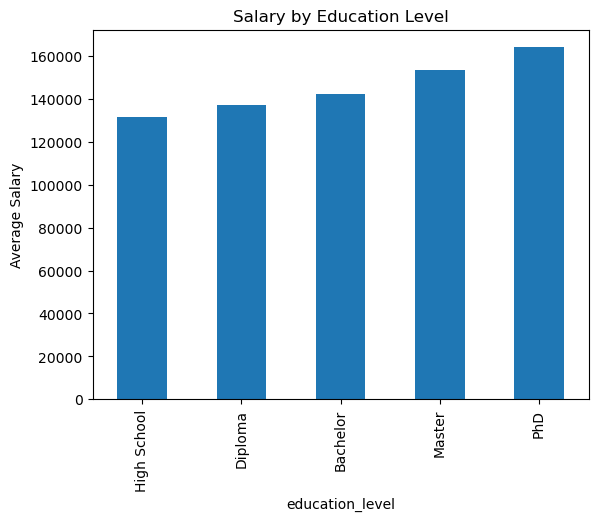

In [17]:
# Code Block 16: visualize the data
avg_salary = df.groupby('education_level')['salary'].mean().sort_values()

avg_salary.plot(kind = 'bar')
plt.ylabel('Average Salary')
plt.title('Salary by Education Level')
plt.show()

# Skills Count and Salary

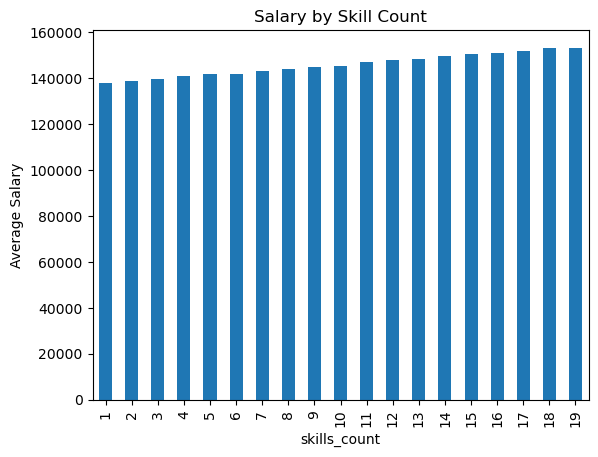

In [18]:
# Code Block 17
avg_salary = df.groupby('skills_count')['salary'].mean().sort_values()

avg_salary.plot(kind = 'bar')
plt.ylabel('Average Salary')
plt.title('Salary by Skill Count')
plt.show()

# Company Size and Salary

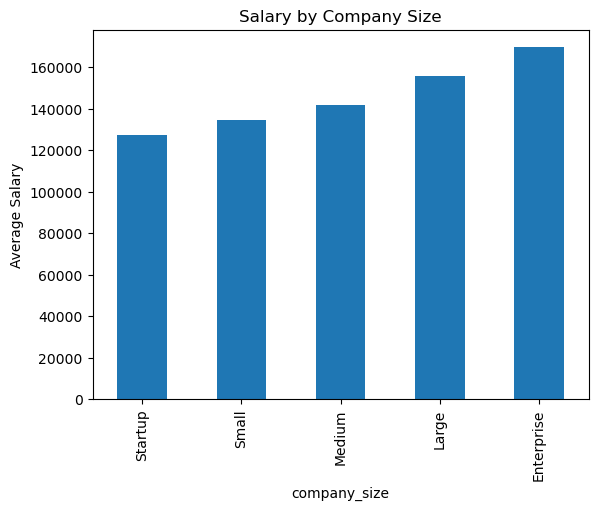

In [19]:
# Code Block 18
avg_salary = df.groupby('company_size')['salary'].mean().sort_values()

avg_salary.plot(kind = 'bar')
plt.ylabel('Average Salary')
plt.title('Salary by Company Size')
plt.show()

# Locations and Salary

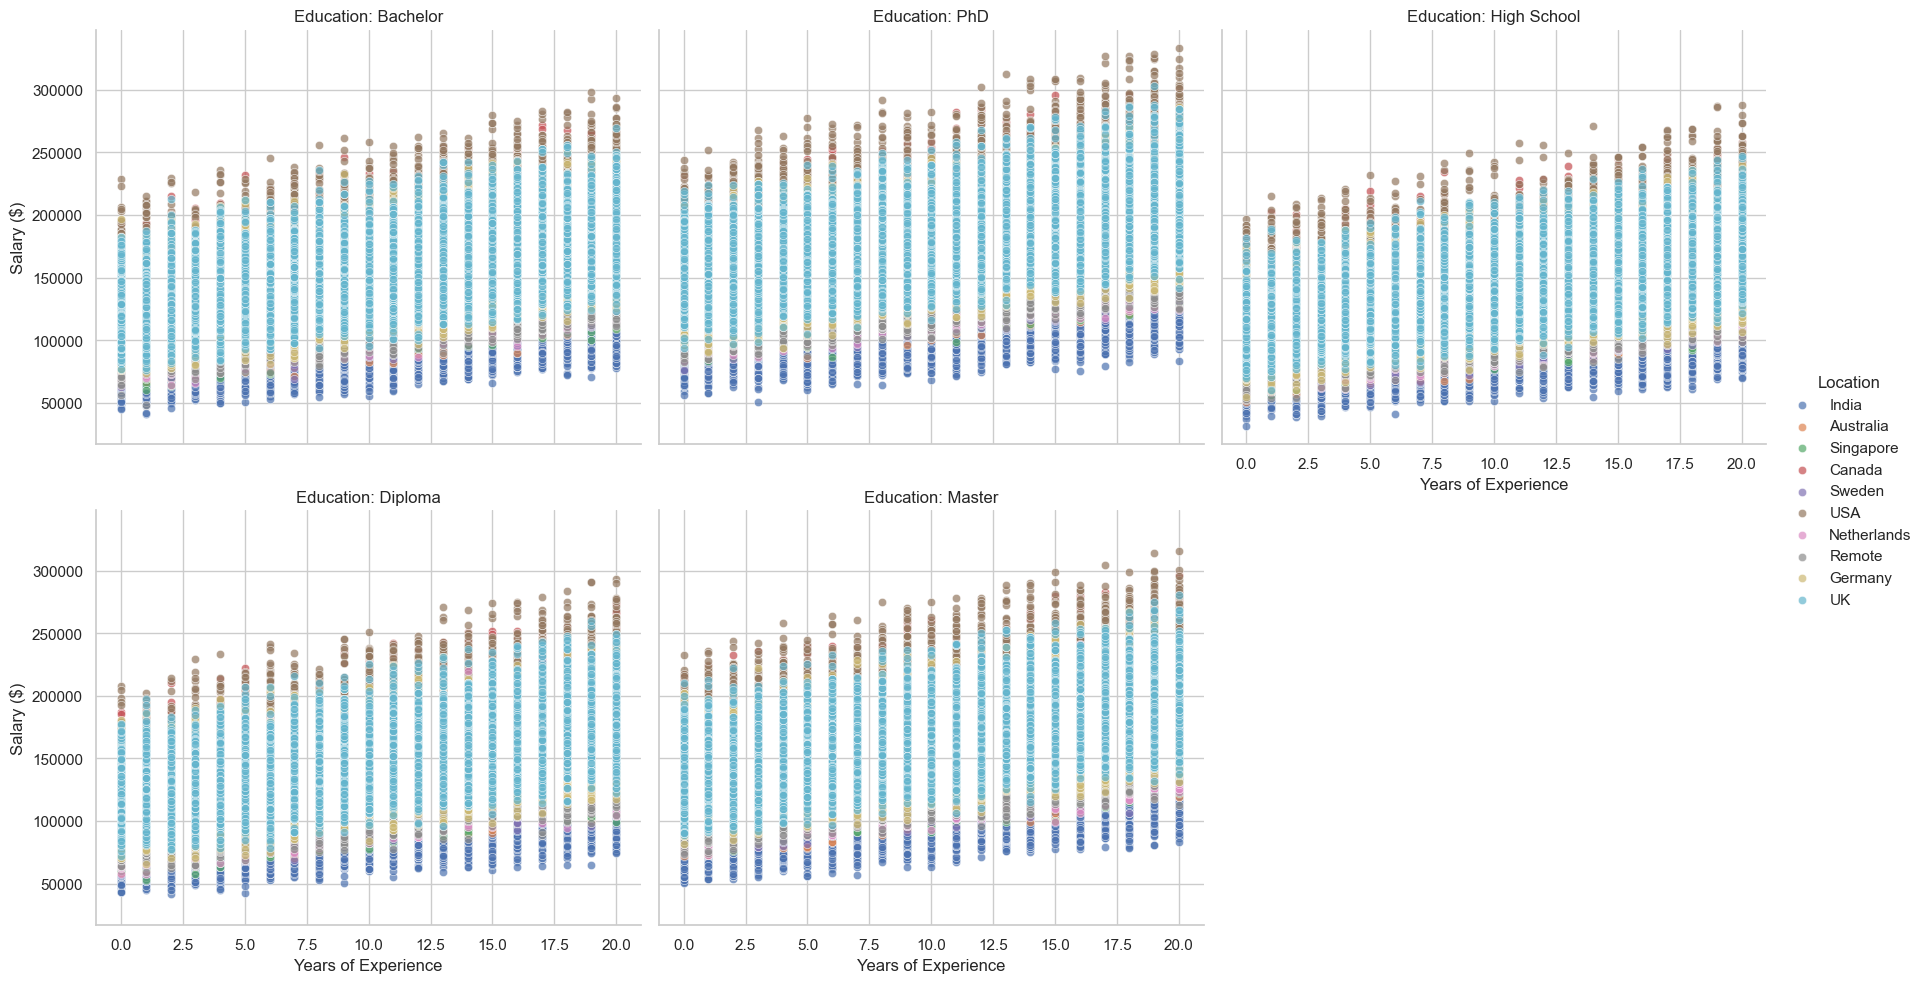

In [20]:
# Code Block 19: visualize the data using a Facet Grid to compare loactions and salaries when controlling for education level and years of 
# experience

sns.set_theme(style="whitegrid")
g = sns.FacetGrid(df, col="education_level", hue="location", height=5, aspect=1.2, col_wrap=3)
g.map(sns.scatterplot, "experience_years", "salary", alpha=0.7)
g.add_legend(title="Location")
g.set_axis_labels("Years of Experience", "Salary ($)")
g.set_titles("Education: {col_name}")
plt.show()

# Visualizing Target Variable (Salary) Distribution

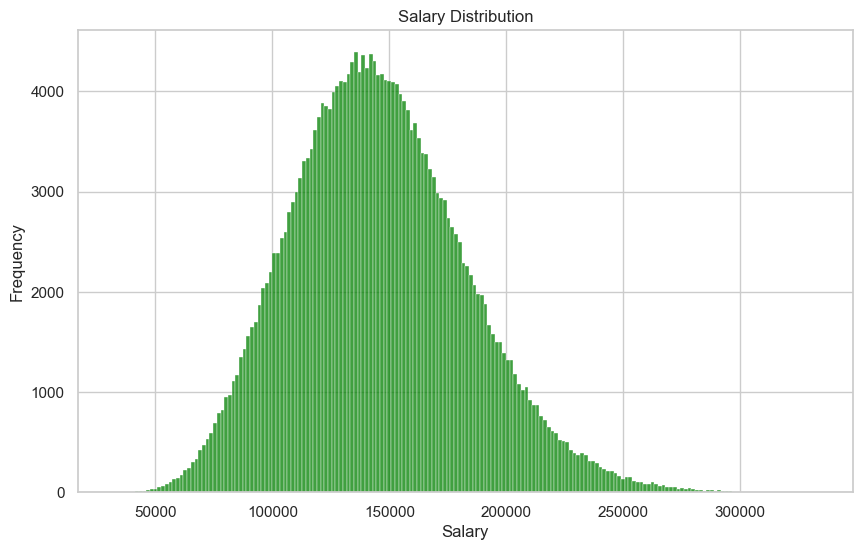

In [23]:
# Code Block 20
plt.figure(figsize = (10, 6))
sns.histplot(df['salary'], color = 'green')
plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.show()

Shows a bell curve, so normal distribution

# Visualizing Years of Experience Distribution

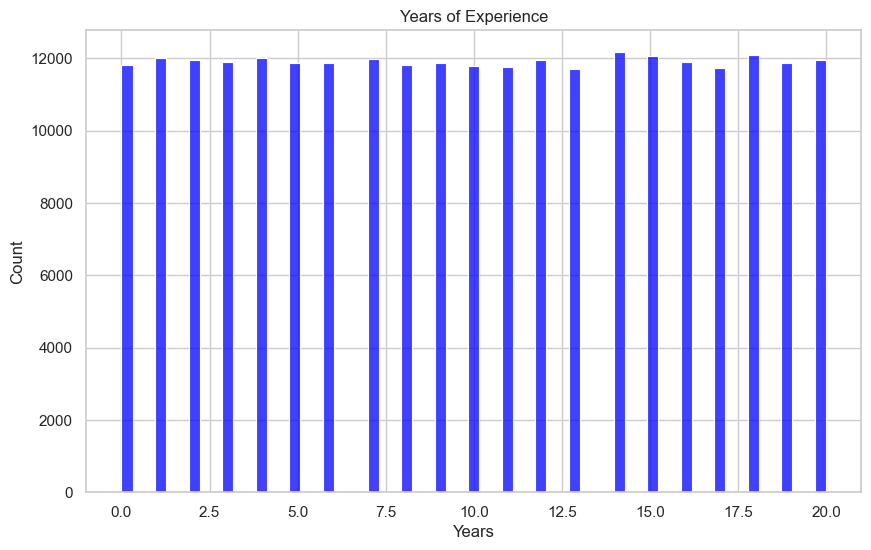

In [24]:
# Code Block 21
plt.figure(figsize = (10, 6))
sns.histplot(df['experience_years'], color = 'blue')
plt.title('Years of Experience')
plt.xlabel('Years')
plt.ylabel('Count')
plt.show()

# Visualizing Skills Count Distribution

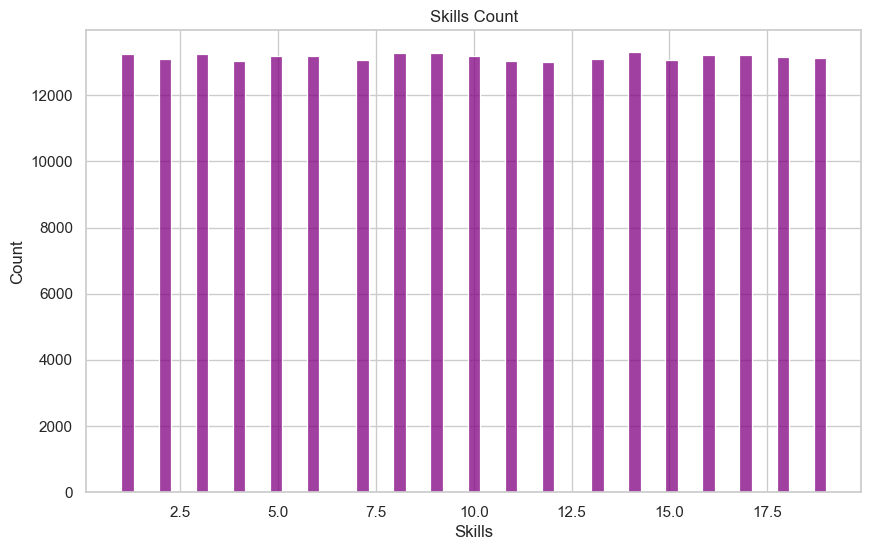

In [25]:
# Code Block 22
plt.figure(figsize = (10, 6))
sns.histplot(df['skills_count'], color = 'purple')
plt.title('Skills Count')
plt.xlabel('Skills')
plt.ylabel('Count')
plt.show()

# Visualizing Company Size

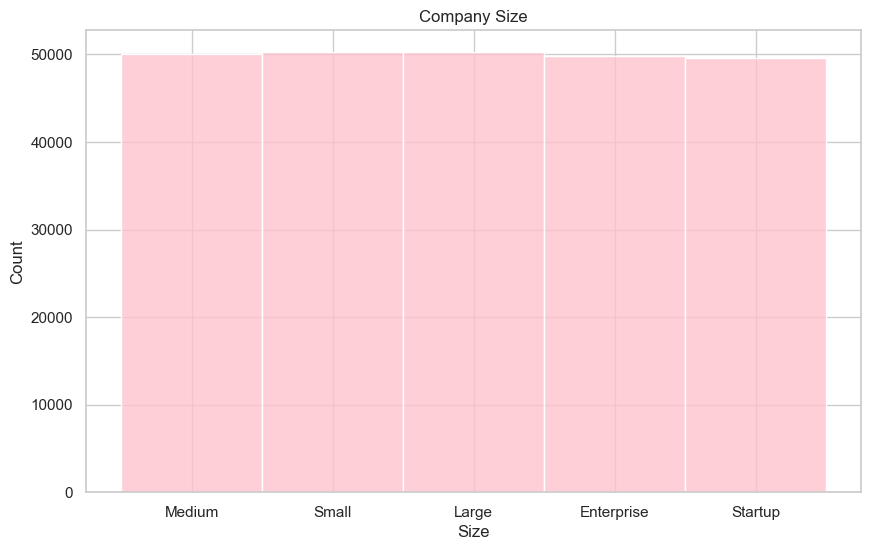

In [26]:
# Code Block 23
plt.figure(figsize = (10, 6))
sns.histplot(df['company_size'], color = 'pink')
plt.title('Company Size')
plt.xlabel('Size')
plt.ylabel('Count')
plt.show()

# Visualizing Location

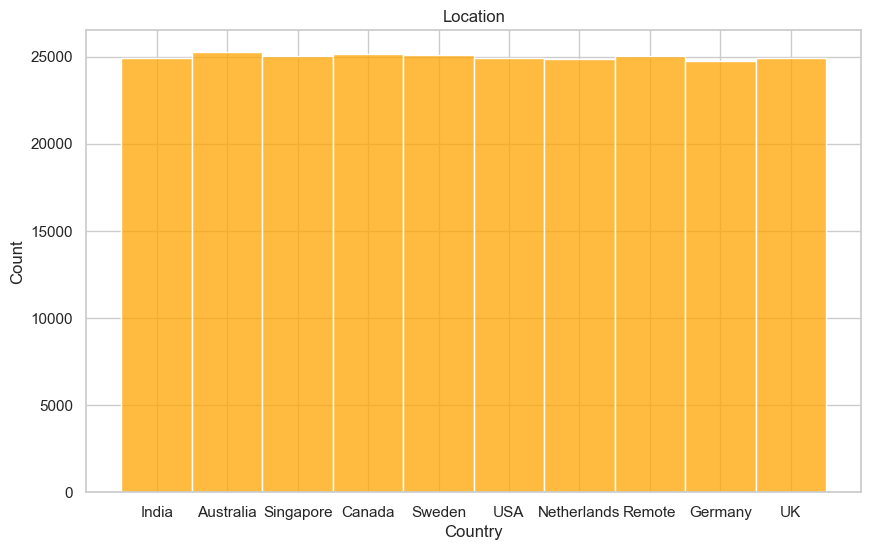

In [28]:
# Code Block 24
plt.figure(figsize = (10, 6))
sns.histplot(df['location'], color = 'orange')
plt.title('Location')
plt.xlabel('Country')
plt.ylabel('Count')
plt.show()

# Feature Engineering

Extra Notes: Education level has a clear trend so it should be treated as such when it is encoded for building the model. This makes it slightly different than regular dummy variables which are not supposed to have a clear trend.
Same goes for company size.

Interaction Variable between education level and experience.

In [54]:
# Code Block 25: Ordinal Encoding
education_order = {
    'High School': 0,
    'Diploma' : 1,
    'Bachelor': 2,
    'Master': 3,
    'PhD': 4
}
df1 = pd.read_csv('job_salary_prediction_dataset.csv', index_col = 0, header = 0)
df1['education_ord'] = df1['education_level'].map(education_order)

In [55]:
# Code Block 26: Sanity Check
print(df1[['education_level', 'education_ord']].drop_duplicates())

                   education_level  education_ord
job_title                                        
AI Engineer               Bachelor              2
Frontend Developer             PhD              4
AI Engineer            High School              0
AI Engineer                Diploma              1
Business Analyst            Master              3


In [56]:
# Code Block 27: creating the interaction variable
df1['edu_exp_int'] = df1['education_ord'] * df1['experience_years']

Ordinal Encoding for Company Size

In [57]:
# Code Block 28
company_order = {
    'Startup': 0,
    'Small' : 1,
    'Medium': 2,
    'Large': 3,
    'Enterprise': 4
}
df1['company_ord'] = df1['company_size'].map(company_order)

In [58]:
# Code Block 29
print(df1[['company_size', 'company_ord']].drop_duplicates())

                company_size  company_ord
job_title                                
AI Engineer           Medium            2
Data Analyst           Small            1
Product Manager        Large            3
AI Engineer       Enterprise            4
Data Analyst         Startup            0


In [59]:
# Code Block 30
df1['com_siz_int'] = df1['company_ord'] * df1['company_size']

In [60]:
# Code Block 31: creating dummy variables
df1 = pd.get_dummies(df1, columns=['industry'], drop_first=True)
df1 = pd.get_dummies(df1, columns=['location'], drop_first=True)
df1 = pd.get_dummies(df1, columns=['remote_work'], drop_first=True)

# Correlation Matrix

Finding if any variables are too heavily correlated

In [61]:
# Code Block 32
df_corr = df1.select_dtypes(include = ['number'])

corr_matrix = df_corr.corr()

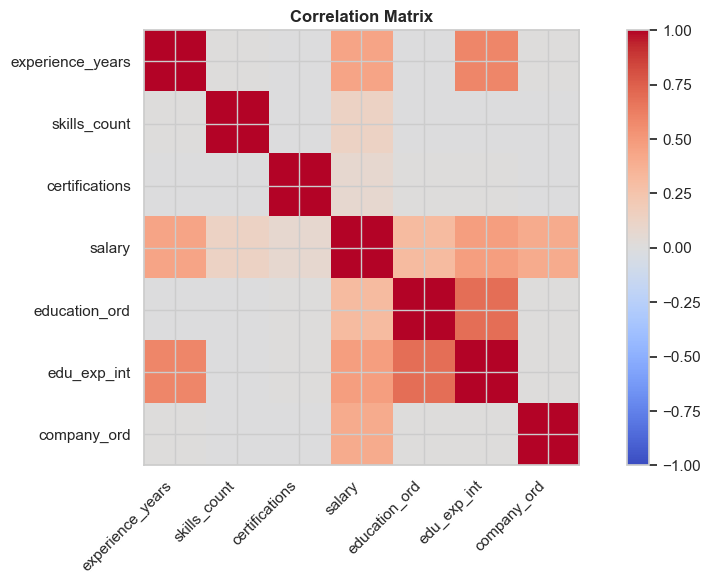

In [62]:
# Code Block 33
fig, ax = plt.subplots(figsize = (10, 6))

cax = ax.imshow(corr_matrix, cmap = 'coolwarm', vmin =-1, vmax = 1)

fig.colorbar(cax)

ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation = 45, ha = 'right')
ax.set_yticklabels(corr_matrix.columns)

ax.set_title("Correlation Matrix", fontsize = 12, weight = 'bold')

plt.tight_layout()
plt.show()

# Splitting the Data Set and Standardizing

In [63]:
# Code Block 35
print(df1.columns)

Index(['experience_years', 'education_level', 'skills_count', 'company_size',
       'certifications', 'salary', 'education_ord', 'edu_exp_int',
       'company_ord', 'com_siz_int', 'industry_Education', 'industry_Finance',
       'industry_Government', 'industry_Healthcare', 'industry_Manufacturing',
       'industry_Media', 'industry_Retail', 'industry_Technology',
       'industry_Telecom', 'location_Canada', 'location_Germany',
       'location_India', 'location_Netherlands', 'location_Remote',
       'location_Singapore', 'location_Sweden', 'location_UK', 'location_USA',
       'remote_work_No', 'remote_work_Yes'],
      dtype='object')


In [64]:
# Code Block 36
df1 = pd.get_dummies(df1, columns=['education_level', 'company_size'])

In [67]:
# Code Block 37
df1 = pd.get_dummies(df1)

In [68]:
# Code Block 38
from sklearn.model_selection import train_test_split

X = df1.drop(columns=['salary'])
y = df1['salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [69]:
# Code Block 39: need to standardize data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Building the Model

The Linear Model

In [71]:
# Code Block 40

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Train model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

# Evaluation
print("R^2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R^2: 0.8000478816460175
RMSE: 16670.518222650597


My R-squared number shows that my model can explain about 80% of the variance in salary.
My RMSE number shows that my prediction is off by about $16.6k.

In [72]:
# Code Block 41: seeing what features drives salary
importance = pd.DataFrame({
    'Feature': X.columns,
    'Impact': model.coef_
})
importance = importance.reindex(importance.Impact.abs().sort_values(ascending=False).index)
print(importance.head(10))

                Feature        Impact
0      experience_years  16440.545910
23         location_USA  12589.017146
17       location_India -12522.562969
15      location_Canada   8371.553109
22          location_UK   6231.843455
3         education_ord   5089.577986
1          skills_count   4702.391840
30  education_level_PhD   4460.355136
5           company_ord   4273.546672
16     location_Germany   4105.876166


In [75]:
# Code Block 42: LASSO MODEL

from sklearn.linear_model import Lasso

# Train Lasso
model = Lasso(alpha = 1.0, max_iter = 10000)
model.fit(X_train_scaled, y_train)

# Predict
y_pred = model.predict(X_test_scaled)

# Evaluate
print("R^2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R^2: 0.8000497479750291
RMSE: 16670.440422163516


In [76]:
# Code Block 43: Showing Feature Importance 

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

feature_importance['abs_coef'] = feature_importance['Coefficient'].abs()

feature_importance = feature_importance.sort_values(
    by = 'abs_coef',
    ascending = False
)

print(feature_importance)

                                              Feature   Coefficient  \
0                                    experience_years  16431.794420   
5                                         company_ord  13291.203542   
23                                       location_USA  12588.879788   
17                                     location_India -12520.908324   
3                                       education_ord  10161.151876   
15                                    location_Canada   8371.434099   
22                                        location_UK   6231.694324   
1                                        skills_count   4701.402854   
16                                   location_Germany   4105.755307   
2                                      certifications   2736.490708   
25                                    remote_work_Yes   2505.385546   
31                            company_size_Enterprise   1841.309553   
33                                company_size_Medium  -1509.734411   
30    